# 文本 03｜从看懂图到自己完成情感分类

这是 RNN 主线的推荐课后实践。先完成训练词表和有效句尾 forward，再训练自己的基础模型；提高、错例分析和手写挑战选一项深入。图片路线保留为独立选做扩展，一周内不要求完成两套工程。

下面先展示任务地图和数据路径，然后才进入 TODO。图帮助你理解要交什么，不会自动实现词表或 forward。基础 TODO 未完成时会明确停止；先阅读提示、补全并重启内核再从头运行。

> **课堂预览**　本页的图是 2026-10-17 的本地 CPU 运行快照，重新执行会更新；人工图解与训练结果已分别标明。只阅读可直接展开输出，实验时仍需从第一格执行。作业只保留 TODO 之前的预览，没有填入答案或作业训练成绩。

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

# 支持从仓库根、03_rnn_lab、当前任务子目录启动，不依赖盘符或安装 rnn_lab。
LAB_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / "03_rnn_lab")
                if (candidate / "rnn_lab").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("请从课程仓库、03_rnn_lab 或本任务目录启动 Notebook。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
DATA_DIR = LAB_DIR / "06_text_classification" / "data"
torch.set_num_threads(1)
from rnn_lab import configure_chinese_font, seed_everything
configure_chinese_font()
from rnn_lab.text_data import (load_text_data, build_vocab, encode_text,
    make_text_dataloaders, text_data_diagnostics, save_text_preprocessing,
    load_text_preprocessing)
from rnn_lab.text_engine import (TextExperimentConfig, run_text_experiment,
    predict_text, evaluate_text_final, export_text_experiments_csv, save_text_run)
from rnn_lab.text_plots import (plot_text_history, plot_text_confusion,
    plot_text_comparison, plot_text_states, text_examples)
print("实验室：", LAB_DIR, "；CPU 线程：", torch.get_num_threads())

实验室： <实验室目录> ；CPU 线程： 1


## 先确定本周要走到哪里

左侧基础是一条完整闭环：输入 → 模型 → 验证 → 解释。三个分支互不依赖，先完成基础就可以提交；挑战更关注实现正确性，不以更高准确率证明能力。

开始前在本页新增自己的 Markdown 记录：“我准备完成……；预计最容易错在……；我会用……来核对。”完成后保留预测与实际差异，不覆盖旧记录。

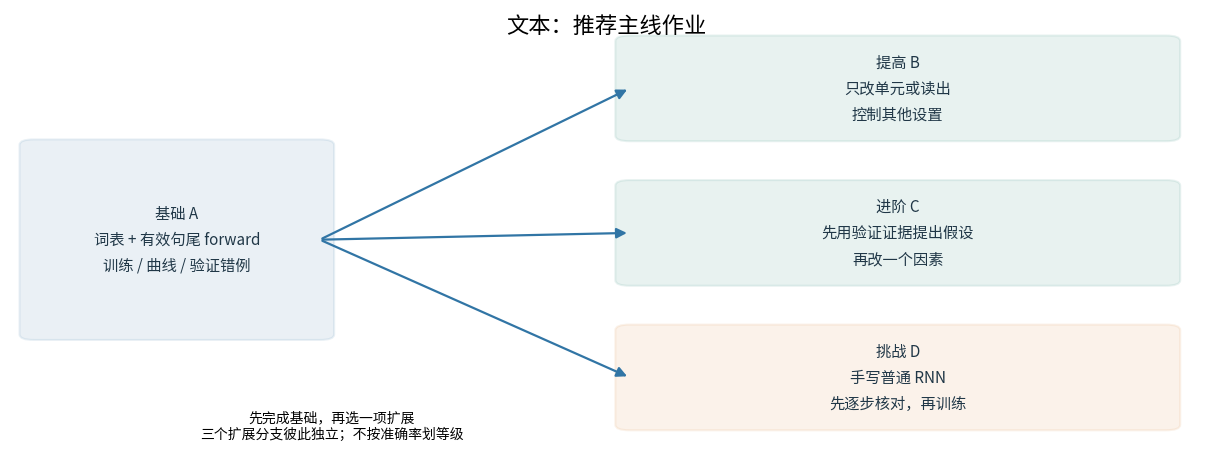

In [2]:
from rnn_lab.teaching_visuals import plot_assignment_route
import matplotlib.pyplot as plt

fig = plot_assignment_route("text")
plt.show()
plt.close(fig)

## 用这张图定位你的 TODO

词表 TODO 位于“字符 → 编号”；forward TODO 位于“循环输出 → 句子表示 → 分类分数”。训练循环和绘图已经提供，先把这两个接口写对，再做训练。

核对时不要只看程序能运行：输入 ID 应是整数，Embedding 后是浮点向量，输出应为 `[B,2]` logits；短句的 PAD 不能混入有效句尾。只检查形状还不够，应再用自己能手算的小例子核对数值。

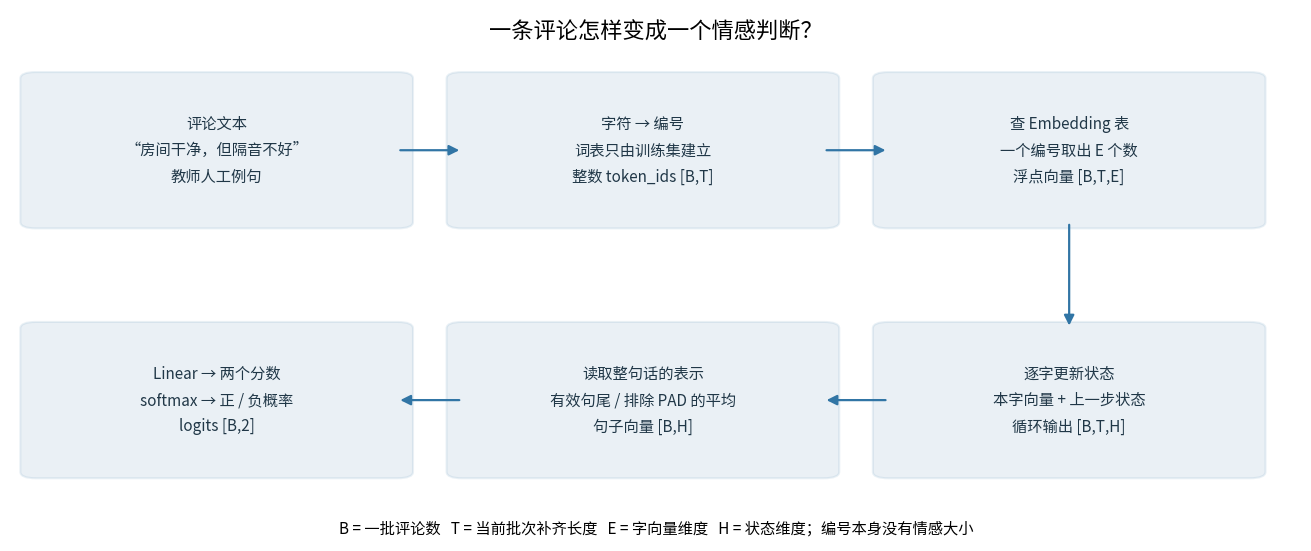

In [3]:
from rnn_lab.teaching_visuals import plot_text_pipeline
import matplotlib.pyplot as plt

fig = plot_text_pipeline()
plt.show()
plt.close(fig)

In [4]:
from dataclasses import replace
from datetime import datetime
import uuid
from rnn_lab.text_data import clean_text

RUN_IMPROVE = False       # 只依赖基础；切单元或改为masked mean，一次改一个因素。
RUN_ANALYSIS = False      # 只依赖基础；依据验证错例提出明确修改并复核。
RUN_MANUAL = False        # 只依赖基础；不用先做提高或进阶。
CHECK_MANUAL_GRADIENTS = False  # 可选，不要求手写反向传播。

IMPROVE_CELL = "gru"      # rnn / lstm / gru
IMPROVE_READOUT = "last"  # last / mean；与A相比只能改变一项。
ANALYSIS_MAX_LENGTH = 140
ANALYSIS_HYPOTHESIS = ""  # 开启进阶前，先依据验证证据写修改理由与局限。

data = load_text_data(DATA_DIR)
base = TextExperimentConfig(
    name="A｜学生 RNN 有效last", cell_type="rnn", embedding_dim=32,
    hidden_size=32, num_layers=1, dropout=0.0, readout="last",
    max_length=100, epochs=6, batch_size=64, learning_rate=0.003,
    seed=42, device="cpu",
)
RUN_DIR = (LAB_DIR / "outputs" / "text" / "03_student" /
           (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]))
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("类别与划分：", data.class_names, {key: len(value) for key, value in data.splits.items()})
print("本轮目录：", RUN_DIR)

类别与划分： ('负面', '正面') {'train': 2000, 'val': 500, 'test': 500}
本轮目录： <实验室目录>\outputs\text\03_student\20261017_134231_e4add6a1


## 基础 TODO 1｜只从训练文本建立词表

接口 `student_build_vocab(texts)` 接收一组训练原文，返回 `{字符:整数ID}`。固定 `<PAD>:0`、`<UNK>:1`，其他 ID 连续且唯一；字符来自 `clean_text` 的结果，排序规则自己选择并说明，使重复运行可复现。不要向函数传入验证/测试文本，也不要调用公共 `build_vocab` 代替自己的实现。

分层提示：先统一清理，再收集字符，最后安排 ID；需要截断的是每条编码序列，不应为了 max_length 丢掉训练词表后半段字符。前面教过字符编码 API，本页要求自己把训练数据边界与可复现编号实现出来。

In [ ]:
def student_build_vocab(texts):
    # TODO 1：自己实现训练集词表；保留 PAD=0、UNK=1；使用统一 clean_text。
    raise NotImplementedError("基础 TODO 1：请自己建立训练集字符词表。")

probe_vocab = student_build_vocab(["甲甲", "乙！"])
assert probe_vocab["<PAD>"] == 0 and probe_vocab["<UNK>"] == 1
assert set(probe_vocab) == {"<PAD>", "<UNK>", "甲", "乙", "!"}
assert sorted(probe_vocab.values()) == list(range(len(probe_vocab)))
assert probe_vocab == student_build_vocab(["甲甲", "乙！"]), "同一输入应产生可复现词表。"
vocab = student_build_vocab(record["text"] for record in data.splits["train"])
assert vocab["<PAD>"] == 0 and vocab["<UNK>"] == 1
print("只由训练集建立词表：", len(vocab))
print("编码诊断：", text_data_diagnostics(data, vocab, base.max_length))

## 基础 TODO 2｜Embedding → 循环层 → 有效句尾 → Linear

构造函数已提供，自己完成 forward。输入 `token_ids:[B,T]`、`lengths:[B]`，输出 `[B,K]` **logits**。默认单向；先得到顶层每步隐藏状态，再为每条句子找到最后一个有效位置。不要无条件用物理末尾，不在 forward 做 softmax。

可以直接处理补齐后的单向输出，再按真实 lengths 读出。RNN/GRU 第二项是 h_n，LSTM 第二项是 `(h_n,c_n)`，第一个返回值都可用于本题。不要改用前面已完成的分类器或直接调用其 forward。

提高的 masked mean 分支现在可以保留 TODO，基础不会调用它。mean 平均的是有效时间轴，排除 PAD，不是平均 batch，也不是平均 Embedding。

In [ ]:
class StudentTextClassifier(torch.nn.Module):
    def __init__(self, vocab_size, n_classes, config):
        super().__init__()
        self.cell_type = config.cell_type
        self.readout = config.readout
        self.embedding = torch.nn.Embedding(vocab_size, config.embedding_dim, padding_idx=0)
        constructor = {"rnn": torch.nn.RNN, "lstm": torch.nn.LSTM, "gru": torch.nn.GRU}[config.cell_type]
        self.recurrent = constructor(config.embedding_dim, config.hidden_size,
                                     num_layers=config.num_layers, batch_first=True,
                                     dropout=config.dropout if config.num_layers > 1 else 0.0)
        self.classifier = torch.nn.Linear(config.hidden_size, n_classes)

    def forward(self, token_ids, lengths):
        if self.readout == "last":
            # TODO 2：查Embedding、调用循环层、按每条真实长度读句尾、Linear。
            raise NotImplementedError("基础 TODO 2：请补全有效句尾 forward，返回 [B,K] logits。")
        # TODO 3（提高选做）：只平均有效时间位置，再接相同分类层。
        raise NotImplementedError("提高 TODO 3：请实现排除 PAD 的 hidden mean。")

seed_everything(base.seed)
probe_model = StudentTextClassifier(len(vocab), len(data.class_names), base)
probe_ids = torch.tensor([[1, 1, 0, 0], [1, 1, 1, 1]], dtype=torch.int64)
probe_lengths = torch.tensor([2, 4], dtype=torch.int64)
probe_model.eval()
with torch.no_grad():
    probe_logits = probe_model(probe_ids, probe_lengths)
    padded_logits = probe_model(torch.nn.functional.pad(probe_ids, (0, 3)), probe_lengths)
    alone_logits = probe_model(probe_ids[:1, :2], probe_lengths[:1])
assert tuple(probe_logits.shape) == (2, len(data.class_names))
assert bool(torch.isfinite(probe_logits).all())
torch.testing.assert_close(probe_logits, padded_logits, atol=1e-6, rtol=1e-5)
torch.testing.assert_close(probe_logits[:1], alone_logits, atol=1e-6, rtol=1e-5)
print("形状、有效句尾、增加右PAD及长短句混批检查通过。")

## 训练支架与基础 A：完成一次闭环

每组重新初始化，固定词表和划分，训练/验证/CSV由公共工具负责。只完成基础时，后面三个分层开关均为 False，直接运行到导出，不需要补任何高阶 TODO。

In [ ]:
def train_student(config, manual=False):
    seed_everything(config.seed)
    model = StudentTextClassifier(len(vocab), len(data.class_names), config)
    if manual:
        from rnn_lab.manual_rnn import StudentRNN
        model.recurrent = StudentRNN(config.embedding_dim, config.hidden_size)
    result = run_text_experiment(config, data, vocab=vocab, model=model, evaluate_test=False)
    result["implementation"] = "student_manual_rnn" if manual else "student_pytorch_recurrent"
    print(config.name, "验证Accuracy=", round(result["val_metrics"]["accuracy"], 4),
          "参数量=", result["parameter_count"], "训练秒数=", round(result["elapsed_seconds"], 3))
    return result

results = {"A": train_student(base)}
fig = plot_text_history(results["A"])
fig.savefig(RUN_DIR / "A_training.png", dpi=140, bbox_inches="tight")
plt.show()

### 基础跑通以后，用图提出一个问题

先读每个分组的分母，再比较错误率。选一个自己能解释的错例，写出真实标签、预测、有效长度、是否截断及未知字情况。这一步属于基础分析，不要求开启进阶训练。

若准备做进阶，把这里的观察写成待验证假设；图中的相关性不能直接作为错误原因。

In [ ]:
from rnn_lab.teaching_visuals import plot_validation_groups
import matplotlib.pyplot as plt

fig = plot_validation_groups(results["A"])
fig.savefig(RUN_DIR / "A_validation_groups.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

## 提高 B：只改变一个因素

可选 RNN→GRU/LSTM，保持 last；或者保持 RNN，自己实现 masked mean。相同 H 不表示不同单元参数量相同，比较时引用实际参数量。先写预测，再开 `RUN_IMPROVE`，不需要做进阶或手写挑战。

In [ ]:
if RUN_IMPROVE:
    if IMPROVE_CELL not in {"rnn", "lstm", "gru"} or IMPROVE_READOUT not in {"last", "mean"}:
        raise ValueError("请使用约定的循环单元和读出方式。")
    changed = int(IMPROVE_CELL != base.cell_type) + int(IMPROVE_READOUT != base.readout)
    if changed != 1:
        raise ValueError("提高实验相对A一次只改变循环单元或读出中的一项。")
    config_b = replace(base, name="B｜只改一个因素", cell_type=IMPROVE_CELL, readout=IMPROVE_READOUT)
    results["B"] = train_student(config_b)
else:
    print("跳过提高：不调用 masked mean TODO，基础可独立完成。")

## 进阶 C：先分析验证错例，再验证一个明确修改

先读 A 的错例和下面按长度/未知字分组的描述。选择一个证据支持的修改；本支架提供只修改 max_length 的例子，也可在保留单因素约束下自行改别的参数。只用验证信息选择，不按 test 改截断长度。

开启前填 `ANALYSIS_HYPOTHESIS`：引用错例或分组数量，说明预期与局限。修改长度不能恢复训练样本之外的信息，长度分组误差也不自动证明截断是原因。

In [ ]:
# 这段分析基础也可运行，使用验证集原有顺序；不触碰测试成绩。
a_metrics = results["A"]["val_metrics"]
groups = {}
for index, record in enumerate(data.splits["val"]):
    info = encode_text(record["text"], vocab, base.max_length)
    key = ("被截断" if info["truncated"] else "未截断",
           "有UNK" if info["unknown_count"] else "无UNK")
    correct = int(a_metrics["predictions"][index]) == record["label"]
    count, hits = groups.get(key, (0, 0))
    groups[key] = count + 1, hits + int(correct)
print("验证分组（小组样本少时谨慎解释）：")
for key, (count, hits) in groups.items():
    print(key, "数量=", count, "正确=", hits, "Accuracy=", round(hits / count, 4))
for example in text_examples(results["A"], correct=False, limit=5):
    print(example)
if RUN_ANALYSIS:
    if not ANALYSIS_HYPOTHESIS.strip():
        raise NotImplementedError("进阶：先填写依据验证证据提出的假设与局限。")
    if ANALYSIS_MAX_LENGTH == base.max_length:
        raise ValueError("本支架只改变最大长度，请设置与A不同的正整数。")
    print("我的假设：", ANALYSIS_HYPOTHESIS)
    config_c = replace(base, name="C｜验证证据驱动长度修改", max_length=ANALYSIS_MAX_LENGTH)
    results["C"] = train_student(config_c)
else:
    print("跳过进阶训练：已保留基础验证错例，未要求完成进阶。")

## 挑战 D：同一份手写 RNN 接入文本

只依赖基础，不要求先完成提高或进阶。在 [公共手写支架](../rnn_lab/manual_rnn.py) 完成 `StudentRNN.step` 和 `forward` 两个 TODO：单层、单向、tanh、显式时间循环、支持批次和可选初始状态。可以自动求导，不能用 nn.RNN / nn.RNNCell 代替核心。

同一份实现也能接入图片路线。先将同一组参数（输入权重、循环权重与两份偏置）复制到手写实现，核对多组 B/T/F/H 的全部输出与最终状态；再复制已训练 A 的 Embedding/分类头，核对最终 logits。最后重新初始化独立训练 D，预算与 A 一致。梯度核对可选，dropout固定为0。

In [ ]:
if RUN_MANUAL:
    from rnn_lab.manual_rnn import (StudentRNN, copy_rnn_weights,
                                    verify_manual_rnn_factory)
    print("多尺寸逐时刻/最终状态核对：", verify_manual_rnn_factory(StudentRNN))
    if CHECK_MANUAL_GRADIENTS:
        from rnn_lab.manual_rnn import verify_manual_rnn
        print("可选梯度核对：", verify_manual_rnn(StudentRNN(5, 7), check_gradients=True))
    reference_model = results["A"]["model"]
    manual_probe = StudentTextClassifier(len(vocab), len(data.class_names), base)
    manual_probe.recurrent = StudentRNN(base.embedding_dim, base.hidden_size)
    manual_probe.embedding.load_state_dict(reference_model.embedding.state_dict())
    manual_probe.classifier.load_state_dict(reference_model.classifier.state_dict())
    copy_rnn_weights(reference_model.recurrent, manual_probe.recurrent)
    reference_model.eval(); manual_probe.eval()
    check_batch = next(iter(results["A"]["loaders"]["val"]))
    with torch.no_grad():
        expected = reference_model(check_batch["token_ids"], check_batch["lengths"])
        actual = manual_probe(check_batch["token_ids"], check_batch["lengths"])
    torch.testing.assert_close(actual, expected, atol=1e-6, rtol=1e-5)
    print("同参数最终分类logits最大误差：", float((actual - expected).abs().max()))
    results["D"] = train_student(replace(base, name="D｜学生手写RNN 有效last"), manual=True)
else:
    print("跳过手写挑战：公共递推 TODO 不影响基础/提高/进阶。")

## 共用收尾：保存多组记录与最终方案

以下所有层次共用。没有完成的组不造空成绩，不仅保存最好一组。模型选型只看验证信息；默认不评价 test。先在报告写选型理由，再开启 `RUN_FINAL_TEST` 并只运行这一格。测试后不根据结果继续换方案。

In [ ]:
RUN_FINAL_TEST = False  # 选型后在本格改True并只运行本格；不要重跑参数格。
selected_key = max(results, key=lambda key: (results[key]["val_metrics"]["accuracy"],
                                            -results[key]["val_metrics"]["loss"]))
selected = results[selected_key]
print("验证选定：", selected_key, selected["config"].name)
fig = plot_text_comparison(list(results.values()))
fig.savefig(RUN_DIR / "all_comparisons.png", dpi=140, bbox_inches="tight")
plt.show()
fig = plot_text_confusion(selected, split="val")
fig.savefig(RUN_DIR / "selected_validation_confusion.png", dpi=140, bbox_inches="tight")
plt.show()
print("自己的额外演示：", predict_text(selected, "虽然位置不错，但是卫生让人失望。"))
if RUN_FINAL_TEST:
    final = evaluate_text_final(selected)
    print("固定模型最终测试：", {key: final[key] for key in ("loss", "accuracy")})
else:
    print("最终测试关闭；test指标留空，不填0。")
for key, result in results.items():
    save_text_run(result, RUN_DIR / key)
export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
print("保留全部记录：", list(results), "；输出：", RUN_DIR)

## 一周安排与提交记录

建议前两天完成两个基础 TODO 和边界检查，第3天完成 A、图与 CSV；第4–5天按能力选提高或验证分析；第6–7天有余力再做手写挑战并整理解释。只完成基础仍可提交完整闭环，图片和文本不要求同时完成。

请在此填写：姓名/学号；完成层次；数据版本与类别映射；训练词表来源及编号规则；B/T/E/H/K与真实长度的解释；一次实验前预测与实际差异；至少两个验证例子；CSV中的参数量、耗时、验证Loss/Accuracy；选型依据及局限。

手写挑战另外提交：逐步数值核对，一个自己定位的错误，对“每一步把状态清零会怎样”的解释，维度变化与权重共享说明。不要只交准确率截图，不要求手写LSTM/GRU或优化器。个人 Notebook、CSV和图保留在自己的输出目录。

自查：TODO由自己完成且能解释；词表只用train；last/mean排除PAD；基础不依赖高阶；验证选型且test默认关闭；未测试项留空；多组记录均保留；没有拿教师人工例句充当正式测试样本。

## 保存与结束

本页输出写入带运行标识的新目录，保留旧记录。先保存 Notebook，再按需运行下一格关闭图片。本页不自动关闭内核；不要为了重新看图反复训练。共享服务器每次只运行一个训练任务。

In [ ]:
# 需要重新实验时建议重启内核，从头运行；本格仅关闭图片。
plt.close("all")